# 03 - Cancellation Analysis ❌

**Business question:** why do customers cancel their bookings, and who is most likely to?

**Questions to answer:**
- What is the overall cancellation rate?
- Does cancellation rate differ by hotel type, customer country, or customer type?
- How does lead time relate to cancellation?
- Does deposit type or a history of prior cancellations predict cancellation?

In [1]:
import sys
sys.path.append('..')

import pandas as pd

from src.config import CLEAN_DATA_PATH
from src.analysis import (
    cancellation_rate_overall,
    cancellation_rate_by,
    cancellation_rate_by_top_countries,
    cancellation_by_lead_time_bucket,
    previous_cancellations_effect,
)
from src.visualization import plot_cancellation_rate_by, plot_cancellation_by_lead_time_bucket

df = pd.read_csv(CLEAN_DATA_PATH)

## Overall cancellation rate

In [2]:
cancel_rate = cancellation_rate_overall(df)
print(f'Overall cancellation rate: {cancel_rate:.2%}')

Overall cancellation rate: 27.52%


## Cancellation rate by hotel type

hotel
City Hotel      0.301027
Resort Hotel    0.234577
Name: is_canceled, dtype: float64

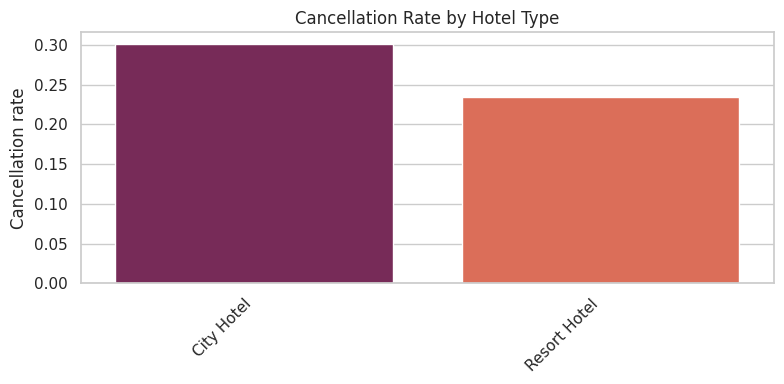

In [3]:
by_hotel = cancellation_rate_by(df, 'hotel')
plot_cancellation_rate_by(by_hotel, 'Cancellation Rate by Hotel Type', '10_cancel_rate_by_hotel.png')
by_hotel

## Cancellation rate by country (top 15 by volume)

country
BRA    0.364777
PRT    0.352833
ITA    0.351307
ESP    0.256925
CHE    0.245367
USA    0.245323
IRL    0.221632
SWE    0.212485
CN     0.206044
BEL    0.197882
FRA    0.196281
DEU    0.195543
GBR    0.190229
NLD    0.183342
AUT    0.179514
Name: is_canceled, dtype: float64

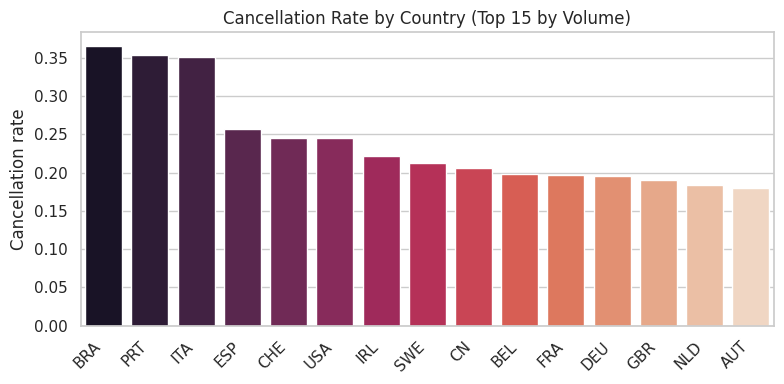

In [4]:
by_country = cancellation_rate_by_top_countries(df, top_n=15)
plot_cancellation_rate_by(by_country, 'Cancellation Rate by Country (Top 15 by Volume)', '11_cancel_rate_by_country.png')
by_country

## Cancellation rate by customer type

customer_type
Transient          0.301379
Contract           0.163317
Transient-Party    0.152529
Group              0.097967
Name: is_canceled, dtype: float64

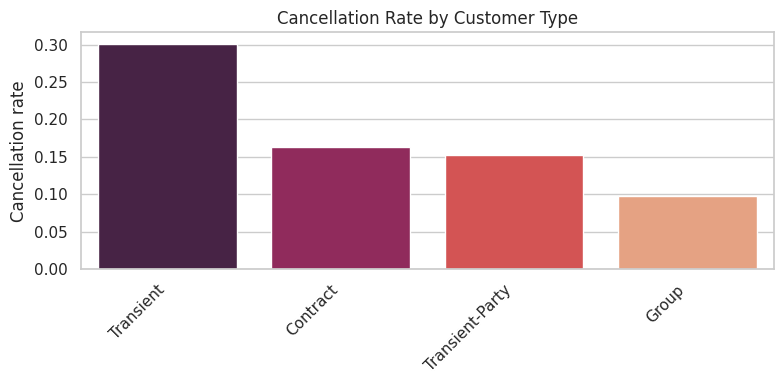

In [5]:
by_customer_type = cancellation_rate_by(df, 'customer_type')
plot_cancellation_rate_by(by_customer_type, 'Cancellation Rate by Customer Type', '12_cancel_rate_by_customer_type.png')
by_customer_type

## Lead time vs cancellation

lead_time
0-7 days      0.084217
8-30 days     0.253804
31-90 days    0.320346
90+ days      0.368591
Name: is_canceled, dtype: float64

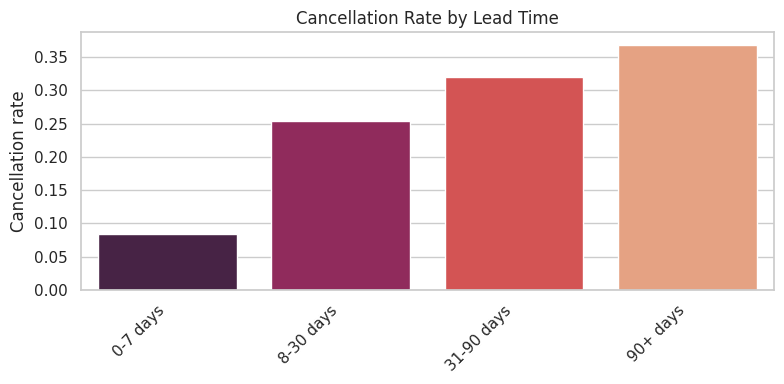

In [6]:
by_lead_time = cancellation_by_lead_time_bucket(df)
plot_cancellation_by_lead_time_bucket(by_lead_time)
by_lead_time

## Deposit type vs cancellation

deposit_type
Non Refund    0.946962
No Deposit    0.267132
Refundable    0.242991
Name: is_canceled, dtype: float64

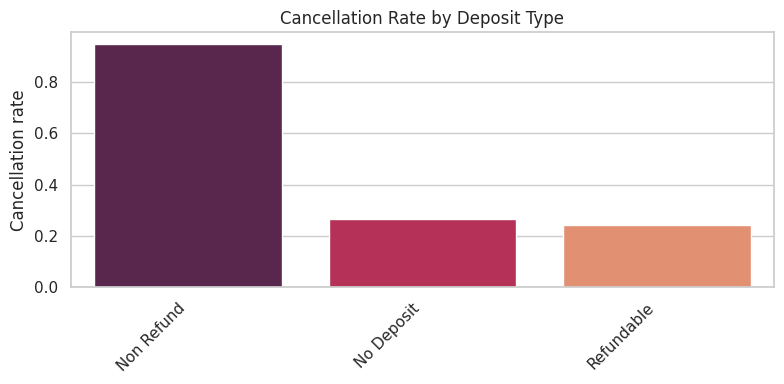

In [7]:
by_deposit = cancellation_rate_by(df, 'deposit_type')
plot_cancellation_rate_by(by_deposit, 'Cancellation Rate by Deposit Type', '13_cancel_rate_by_deposit.png')
by_deposit

## Previous cancellations vs cancellation

previous_cancellations
Has prior cancellation    0.679952
No prior cancellation     0.267231
Name: is_canceled, dtype: float64

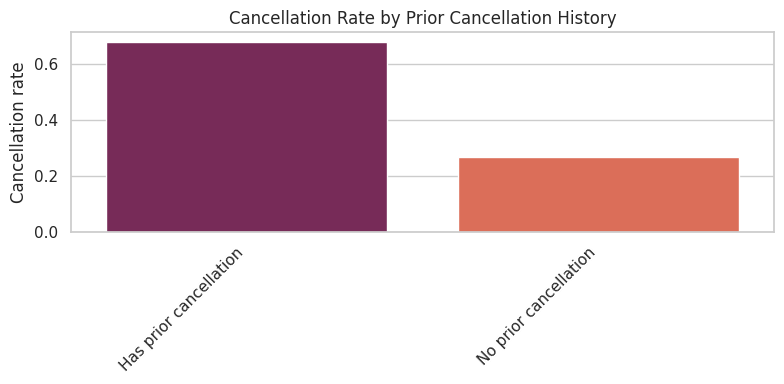

In [8]:
prior_effect = previous_cancellations_effect(df)
plot_cancellation_rate_by(prior_effect, 'Cancellation Rate by Prior Cancellation History', '14_cancel_rate_by_prior_history.png')
prior_effect

## Key insight

In [9]:
ratio = by_lead_time.iloc[-1] / by_lead_time.iloc[0]
riskiest_deposit = by_deposit.idxmax()
print(f"- Bookings made {by_lead_time.index[-1]} in advance cancel at {ratio:.1f}x the rate of {by_lead_time.index[0]} bookings.")
print(f"- '{riskiest_deposit}' deposit bookings have the highest cancellation rate ({by_deposit.max():.1%}) — counterintuitive, since a non-refundable deposit should discourage cancellation; in this dataset it's associated with a specific high-risk booking channel.")
print(f"- Guests with a prior cancellation on record cancel again far more often than first-timers.")

- Bookings made 90+ days in advance cancel at 4.4x the rate of 0-7 days bookings.
- 'Non Refund' deposit bookings have the highest cancellation rate (94.7%) — counterintuitive, since a non-refundable deposit should discourage cancellation; in this dataset it's associated with a specific high-risk booking channel.
- Guests with a prior cancellation on record cancel again far more often than first-timers.
